# Actuariat-01 — Du risque à la prime en C#

**Navigation** · [Sommaire de l’actuariat](README.md) · [Version Python](Actuariat-01-Prime-Pure-Chargement.ipynb) · [Mutualisation partielle](Actuariat-02-Freq-Sev-Hierarchique-CSharp.ipynb)

Un portefeuille auto cumule les petits sinistres, tandis qu’un portefeuille de responsabilité civile médicale concentre le risque dans les grandes pertes. À partir de ces deux profils, vous calculerez la prime pure, estimerez son incertitude, puis étudierez ce que le chargement change pour l’assureur et les assurés.

**Prérequis** · Lois de Poisson et lognormale, espérance, quantile et introduction aux distributions a posteriori. Exécutez avec **.NET (C#)** et un CPython 3.13 fournissant PyMC 6.0.1, ArviZ 1.1.0 et NumPy 2.4.3. Les calculs, simulations et décisions sont en C#. Infer.NET calcule la fréquence conjuguée. PyMC fournit les tirages de sévérité non conjugués.

In [1]:
#r "nuget: MathNet.Numerics,5.0.0"
#r "nuget: Microsoft.ML.Probabilistic,0.4.2504.701"
#r "nuget: Microsoft.ML.Probabilistic.Compiler,0.4.2504.701"
#r "nuget: pythonnet,3.1.0"
#load "../../../Config/PythonNetLoader.cs"
using Microsoft.ML.Probabilistic.Models;

#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Security;
using System.Text;
using System.Text.Json;
using MathNet.Numerics.Distributions;
using Microsoft.DotNet.Interactive.Formatting;
using Python.Runtime;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record ActuFigure(string Markup);
Formatter.Register<ActuFigure>((figure, writer) => writer.Write(figure.Markup), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(ActuFigure), "image/svg+xml");

static void RequireActu(bool condition, string explanation)
{
    if (!condition) throw new InvalidOperationException(explanation);
}

// Le quantile linéaire NumPy correspond à une interpolation entre deux statistiques d'ordre.
static double QuantileActu(IEnumerable<double> values, double probability)
{
    var sorted = values.Order().ToArray();
    double index = probability * (sorted.Length - 1);
    int lower = (int)Math.Floor(index);
    int upper = Math.Min(lower + 1, sorted.Length - 1);
    return sorted[lower] + (index - lower) * (sorted[upper] - sorted[lower]);
}

// Le dénominateur n convient aux tirages qui constituent la distribution représentée.
static double StdActu(IReadOnlyCollection<double> values)
{
    double mean = values.Average();
    return Math.Sqrt(values.Sum(value => Math.Pow(value - mean, 2)) / values.Count);
}

// Le petit contrat JSON ne transfère que les paramètres du graphe et les résultats de l'inférence.
static T InferenceActu<T>(string program, object request)
{
    using var gil = Py.GIL();
    using var scope = Py.CreateScope();
    using var data = new PyString(JsonSerializer.Serialize(request));
    scope.Set("request_json", data);
    scope.Exec(program);
    return JsonSerializer.Deserialize<T>(scope.Get<string>("response_json"))
        ?? throw new InvalidOperationException("Le moteur n’a pas renvoyé de posterior.");
}

static string PyVersionActu(string package)
{
    using var gil = Py.GIL();
    using var module = Py.Import(package);
    using var version = module.GetAttr("__version__");
    return version.As<string>();
}

record ActuSeries(string Name, string Color, double[] X, double[] Y, bool Scatter = false);

static void PlotActu(string title, string xLabel, string yLabel, params ActuSeries[] series)
{
    // Les limites suivent les données plutôt que les résultats d'un run de référence.
    const int left = 82, top = 52, width = 660, height = 240;
    double xMin = series.SelectMany(s => s.X).Min(), xMax = series.SelectMany(s => s.X).Max();
    double yMin = series.SelectMany(s => s.Y).Min(), yMax = series.SelectMany(s => s.Y).Max();
    if (xMin == xMax) xMax += 1;
    if (yMin == yMax) yMax += 1;
    static string F(double v) => v.ToString("G5", CultureInfo.InvariantCulture);
    static string E(string v) => SecurityElement.Escape(v)!;
    double X(double v) => left + width * (v - xMin) / (xMax - xMin);
    double Y(double v) => top + height * (yMax - v) / (yMax - yMin);
    var svg = new StringBuilder();
    svg.Append($"<svg xmlns='http://www.w3.org/2000/svg' role='img' aria-label='{E(title)}' viewBox='0 0 790 410' width='790'><rect width='100%' height='100%' fill='white'/>");
    svg.Append($"<g font-family='system-ui,sans-serif' fill='#172742' font-size='13'><text x='{left}' y='28' font-size='17' font-weight='bold'>{E(title)}</text>");
    for (int tick = 0; tick <= 5; tick++)
    {
        double part = tick / 5.0, zx = left + width * part, zy = top + height * (1 - part);
        svg.Append($"<path d='M{left} {F(zy)}H{left + width}' stroke='#d9e1e8'/><text x='{left - 8}' y='{F(zy + 4)}' text-anchor='end'>{F(yMin + part * (yMax - yMin))}</text>");
        svg.Append($"<text x='{F(zx)}' y='{top + height + 20}' text-anchor='middle'>{F(xMin + part * (xMax - xMin))}</text>");
    }
    svg.Append($"<path d='M{left} {top}V{top + height}H{left + width}' stroke='#526479' fill='none'/><text x='{left + width / 2}' y='340' text-anchor='middle'>{E(xLabel)}</text><text x='22' y='175' transform='rotate(-90 22 175)' text-anchor='middle'>{E(yLabel)}</text>");
    for (int i = 0; i < series.Length; i++)
    {
        var s = series[i];
        // Les séries catégorielles gardent leurs points individuels, même lorsque deux taux se confondent.
        var points = s.X.Zip(s.Y, (x, y) => (X: X(x), Y: Y(y))).ToArray();
        if (!s.Scatter)
        {
            string path = string.Join(" ", points.Select(p => $"{F(p.X)},{F(p.Y)}"));
            svg.Append($"<polyline points='{path}' fill='none' stroke='{s.Color}' stroke-width='2.4'/>");
        }
        else
        {
            foreach (var point in points)
                svg.Append($"<circle cx='{F(point.X)}' cy='{F(point.Y)}' r='3.2' fill='{s.Color}'/>");
        }
        int keyX = left + i % 2 * 320, keyY = 365 + i / 2 * 20;
        svg.Append($"<rect x='{keyX}' y='{keyY - 9}' width='18' height='8' fill='{s.Color}'/><text x='{keyX + 25}' y='{keyY}'>{E(s.Name)}</text>");
    }
    svg.Append("</g></svg>");
    display(new ActuFigure(svg.ToString()));
}

// Le noyau .NET charge le CPython qui sait importer PyMC. Aucun service distant n’est requis.
if (PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "pymc") is not null)
    PythonEngine.BeginAllowThreads();
Console.WriteLine($".NET {Environment.Version} | MathNet 5.0.0 | Infer.NET 0.4.2504.701 | PyMC {PyVersionActu("pymc")} | ArviZ {PyVersionActu("arviz")}");

Installing Packages MathNet.Numerics Microsoft.ML.Probabilistic Microsoft.ML.Probabilistic.Compiler pythonnet

.NET 10.0.14 | MathNet 5.0.0 | Infer.NET 0.4.2504.701 | PyMC 6.0.1 | ArviZ 1.1.0


## 1. Le prix individuel du risque

Pour une richesse de 100 000 € et trois gains possibles de −2 000, 1 000 et 4 000 €, pondérés par 20 %, 50 % et 30 %, l’utilité CRRA fait baisser l’équivalent certain sous le gain moyen. La différence est une prime de risque **individuelle**, liée à la richesse et à l’aversion au risque. L’assureur utilise pour sa prime pure l’espérance du coût des sinistres.

In [2]:
// L’utilité porte sur la richesse totale, puis on retire la richesse initiale de l’équivalent certain.
const double initialWealth = 100_000.0, riskAversion = 0.5;
double[] gains = [-2_000, 1_000, 4_000];
double[] weights = [.2, .5, .3];
double expectedGain = gains.Zip(weights, (gain, weight) => gain * weight).Sum();
double averageUtility = gains.Zip(weights, (gain, weight) =>
    weight * Math.Pow(initialWealth + gain, 1 - riskAversion) / (1 - riskAversion)).Sum();
double certain = Math.Pow((1 - riskAversion) * averageUtility, 1 / (1 - riskAversion)) - initialWealth;
RequireActu(certain < expectedGain, "L’équivalent certain d’une loterie non dégénérée doit diminuer ici.");
Console.WriteLine($"Gain moyen {expectedGain:F0} € | certain {certain:F2} € | prime de risque {expectedGain - certain:F2} €");

Gain moyen 1300 € | certain 1289.10 € | prime de risque 10.90 €


## 2. Fréquence et sévérité lorsque les paramètres sont connus

Pour une fréquence $N$ de loi de Poisson et des sinistres indépendants de coût $S$ lognormal, la perte composée $Y$ vérifie $\mathbb{E}[Y]=\lambda\exp(\mu+\sigma^2/2)$. On garde les deux portefeuilles à leurs échelles originales.

In [3]:
record Portfolio(string Name, double Frequency, double Median, double Sigma)
{
    // Ces deux grandeurs relient la loi conditionnelle de sévérité à la prime annuelle.
    public double Mu => Math.Log(Median);
    public double MeanSeverity => Math.Exp(Mu + Sigma * Sigma / 2);
    public double NetPremium => Frequency * MeanSeverity;
}
Portfolio[] portfolio = [new("A_auto", 0.80, 1_200, 0.9), new("B_rc_med", 0.05, 90_000, 1.1)];
foreach (var p in portfolio)
    Console.WriteLine($"{p.Name,-12} λ={p.Frequency:F2} | médiane {p.Median,8:F0} € | E[S] {p.MeanSeverity,9:F0} € | prime {p.NetPremium,8:F0} €");

A_auto       λ=0.80 | médiane     1200 € | E[S]      1799 € | prime     1439 €


B_rc_med     λ=0.05 | médiane    90000 € | E[S]    164813 € | prime     8241 €


### Loi composée et quantiles

On simule 20 000 assurés-années par portefeuille. Les quantiles portent sur la distribution complète. Le graphique tronque seulement l’axe des grandes pertes au quantile 99 des observations strictement positives.

A_auto: 20000 assurés-années | moyenne 1466 € (ET Monte-Carlo 17 €) | P(Y>π) 0.322 | Q95 6060 € | Q99,5 13829 €


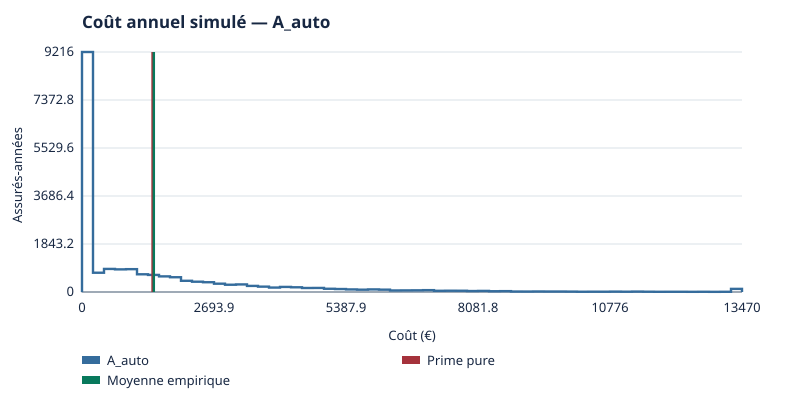

B_rc_med: 20000 assurés-années | moyenne 8041 € (ET Monte-Carlo 477 €) | P(Y>π) 0.047 | Q95 0 € | Q99,5 369060 €


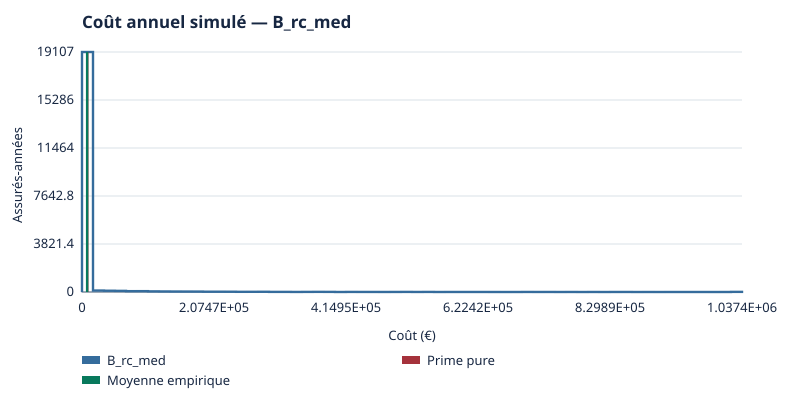

In [4]:
static double CompoundLoss(Portfolio p, Random random)
{
    // Le nombre de pertes est tiré avant les sévérités conditionnelles.
    int claims = Poisson.Sample(random, p.Frequency);
    double loss = 0;
    for (int j = 0; j < claims; j++)
        loss += LogNormal.Sample(random, p.Mu, p.Sigma);
    return loss;
}

static ActuSeries HistogramActu(double[] values, double limit, int bins, string name, string color, bool density)
{
    // La dernière classe reçoit la queue représentée. Les quantiles restent non tronqués.
    var height = new double[bins];
    double step = limit / bins;
    foreach (double value in values)
    {
        int bin = Math.Min(bins - 1, (int)(value / step));
        height[bin] += density ? 1.0 / (values.Length * step) : 1.0;
    }
    var x = new double[2 * bins + 2];
    var y = new double[x.Length];
    for (int i = 0; i < bins; i++)
    {
        x[2 * i + 1] = i * step;
        x[2 * i + 2] = (i + 1) * step;
        y[2 * i + 1] = y[2 * i + 2] = height[i];
    }
    x[^1] = limit;
    return new ActuSeries(name, color, x, y);
}

var randomLoss = new Random(20260825);
var annualLoss = portfolio.ToDictionary(
    p => p.Name,
    p => Enumerable.Range(0, 10 * 2_000).Select(_ => CompoundLoss(p, randomLoss)).ToArray());
foreach (var p in portfolio)
{
    // La variance d’une loi composée de Poisson est λ E[S²].
    double[] losses = annualLoss[p.Name];
    double standardError = Math.Sqrt(p.Frequency * Math.Exp(2 * p.Mu + 2 * p.Sigma * p.Sigma) / losses.Length);
    RequireActu(Math.Abs(losses.Average() - p.NetPremium) < 5 * standardError, "La simulation de la loi composée s’écarte de son contrôle analytique.");
    Console.WriteLine($"{p.Name}: {losses.Length} assurés-années | moyenne {losses.Average():F0} € (ET Monte-Carlo {standardError:F0} €) | P(Y>π) {losses.Count(y => y > p.NetPremium)/(double)losses.Length:F3} | Q95 {QuantileActu(losses, .95):F0} € | Q99,5 {QuantileActu(losses, .995):F0} €");
    double clip = QuantileActu(losses.Where(y => y > 0), .99);
    var hist = HistogramActu(losses, clip, 60, p.Name, "#356c9c", false);
    PlotActu("Coût annuel simulé — " + p.Name, "Coût (€)", "Assurés-années", hist,
        new ActuSeries("Prime pure", "#a5323b", [p.NetPremium, p.NetPremium], [0, hist.Y.Max()]),
        new ActuSeries("Moyenne empirique", "#08795c", [losses.Average(), losses.Average()], [0, hist.Y.Max()]));
}

### Lecture de la loi composée

Dans les deux échantillons, le risque auto se traduit par une masse non nulle bien plus fréquente. Le risque médical donne ici un Q95 nul alors que son Q99,5 dépasse 350 000 €. La masse au coût nul dépend d’abord de la fréquence. Le quantile élevé du portefeuille médical est sensible aux sinistres rares, alors même que son quantile 95 peut se trouver à zéro. L’erreur standard Monte-Carlo donne une échelle de comparaison entre la moyenne simulée et la prime analytique.

### Cas frontière de la mutualisation

Gardons la fréquence de B et sa médiane de sévérité. Une loi de Pareto de forme $\alpha=0{,}9$ possède une médiane mais une espérance infinie. La simulation compare la médiane des moyennes empiriques sur vingt répétitions, pour cinq tailles de portefeuille.

n=     100 | lognormale médiane       5910 € | Pareto médiane         7236 €


n=   1,000 | lognormale médiane       8392 € | Pareto médiane        20589 €


n=  10,000 | lognormale médiane       8596 € | Pareto médiane        26681 €


n= 100,000 | lognormale médiane       8293 € | Pareto médiane        37621 €


n=1,000,000 | lognormale médiane       8236 € | Pareto médiane        47392 €


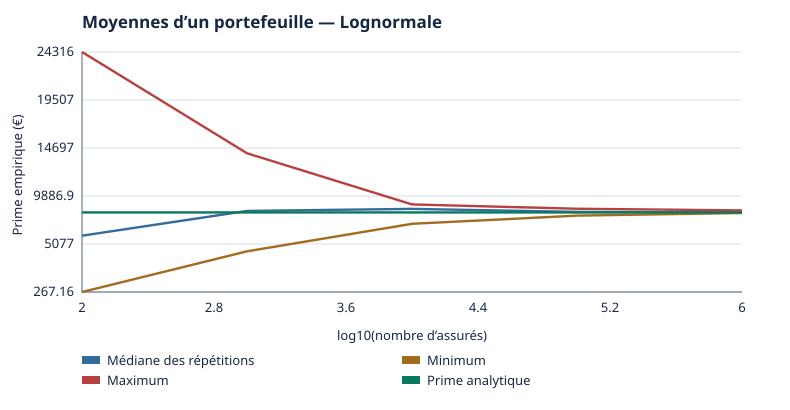

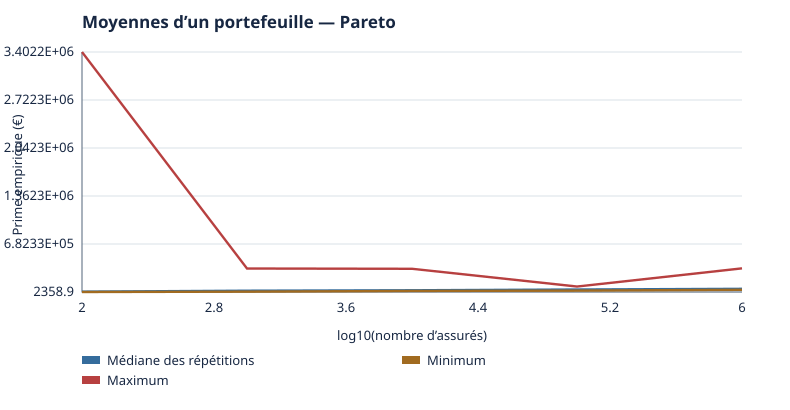

In [5]:
const double paretoAlpha = 0.9;
var bPortfolio = portfolio[1];
double paretoMin = bPortfolio.Median / Math.Pow(2, 1 / paretoAlpha);
int[] portfolioSizes = [100, 1_000, 10_000, 100_000, 1_000_000];
const int repetitions = 20;
var randomTail = new Random(20261119);
var tailResults = new Dictionary<string, double[][]>();
foreach (string law in new[] { "Lognormale", "Pareto" })
{
    var bySize = new List<double[]>();
    foreach (int n in portfolioSizes)
    {
        var premiums = new double[repetitions];
        for (int run = 0; run < repetitions; run++)
        {
            // L’agrégation de Poissons permet de tirer les sinistres du portefeuille en un appel.
            int claims = Poisson.Sample(randomTail, bPortfolio.Frequency * n);
            double amount = 0.0;
            for (int j = 0; j < claims; j++)
                amount += law == "Lognormale"
                    ? LogNormal.Sample(randomTail, bPortfolio.Mu, bPortfolio.Sigma)
                    : paretoMin / Math.Pow(1.0 - randomTail.NextDouble(), 1.0 / paretoAlpha);
            premiums[run] = amount / n;
        }
        bySize.Add(premiums);
    }
    tailResults[law] = bySize.ToArray();
}
var logSize = portfolioSizes.Select(n => Math.Log10(n)).ToArray();
for (int i = 0; i < portfolioSizes.Length; i++)
    Console.WriteLine($"n={portfolioSizes[i],8:N0} | lognormale médiane {QuantileActu(tailResults["Lognormale"][i], .5),10:F0} € | Pareto médiane {QuantileActu(tailResults["Pareto"][i], .5),12:F0} €");

foreach (var (law, values) in tailResults)
{
    var med = values.Select(x => QuantileActu(x, .5)).ToArray();
    var curves = new List<ActuSeries> {
        new("Médiane des répétitions", "#356c9c", logSize, med),
        new("Minimum", "#a16b20", logSize, values.Select(v => v.Min()).ToArray()),
        new("Maximum", "#b74040", logSize, values.Select(v => v.Max()).ToArray())
    };
    if (law == "Lognormale")
        curves.Add(new("Prime analytique", "#08795c", logSize, logSize.Select(_ => bPortfolio.NetPremium).ToArray()));
    PlotActu($"Moyennes d’un portefeuille — {law}", "log10(nombre d’assurés)", "Prime empirique (€)", curves.ToArray());
}
RequireActu(tailResults.Values.SelectMany(v => v).All(x => x.Length == 20 && x.All(double.IsFinite)), "Simulation de queue incomplète.");

### Lecture de la sensibilité à la queue

La ligne analytique est disponible pour la lognormale. Sous Pareto, l’échelle des moyennes varie avec les pertes extrêmes. Les minima et maxima donnent une lecture de la dispersion sur les répétitions, sans servir d’intervalle de confiance.

### Exercice 1 — Assurance habitation

Un portefeuille habitation a $\lambda=0{,}15$, une sévérité lognormale de médiane 2 800 € et $\sigma=1{,}0$. Calculez sa prime pure puis sa prime commerciale avec un chargement de 10 %. Interprétez les unités.

In [6]:
static (double Pure, double Commerciale)? CalculerTarifHabitation(double fréquence, double médiane, double écartTypeLog, double chargement)
{
    // TODO étudiant : obtenir la moyenne lognormale, puis calculer les deux primes.
    return null;
}
var habitation = CalculerTarifHabitation(.15, 2_800, 1.0, .10);
if (habitation is { } tarifs)
{
    RequireActu(tarifs.Pure > 0 && tarifs.Commerciale > tarifs.Pure &&
        Math.Abs(tarifs.Commerciale * .90 - tarifs.Pure) < 1e-8, "Vérifiez la convention multiplicative.");
    Console.WriteLine($"Habitation : pure {tarifs.Pure:F2} € | commerciale {tarifs.Commerciale:F2} €");
}
else
    Console.WriteLine("À compléter : fréquence × espérance du coût, puis chargement.");

À compléter : fréquence × espérance du coût, puis chargement.


## 3. Deux historiques, une même vérité générative

Soixante assurés de type B sont suivis durant trois ou trente ans. Les comptages annuels et coûts individuels alimentent des modèles distincts. Les tirages C# conservent la même loi que ceux du carnet Python. Les générateurs peuvent produire des historiques différents.

In [7]:
record History(string Name, int[] Counts, double[] Severity);
// Un historique de trois ans et un de trente partagent la même fréquence et la même loi de coût.
var historyRandom = new Random(7);
const int insuredB = 60;
var youngCounts = Enumerable.Range(0, 3).Select(_ => Poisson.Sample(historyRandom, insuredB * bPortfolio.Frequency)).ToArray();
var matureCounts = Enumerable.Range(0, 30).Select(_ => Poisson.Sample(historyRandom, insuredB * bPortfolio.Frequency)).ToArray();
History[] histories = [
    new("B_jeune", youngCounts, Enumerable.Range(0, youngCounts.Sum()).Select(_ => LogNormal.Sample(historyRandom, bPortfolio.Mu, bPortfolio.Sigma)).ToArray()),
    new("B_mature", matureCounts, Enumerable.Range(0, matureCounts.Sum()).Select(_ => LogNormal.Sample(historyRandom, bPortfolio.Mu, bPortfolio.Sigma)).ToArray())
];
foreach (var h in histories)
{
    RequireActu(h.Counts.Sum() == h.Severity.Length && h.Severity.All(s => s > 0), "Les coûts doivent correspondre aux comptages.");
    Console.WriteLine($"{h.Name}: {h.Counts.Length} ans | {h.Severity.Length} sinistres | min {h.Severity.Min():F0} € | médiane {QuantileActu(h.Severity, .5):F0} € | max {h.Severity.Max():F0} €");
}
Console.WriteLine($"Comptages annuels du jeune portefeuille : {string.Join(", ", youngCounts)}.");

B_jeune: 3 ans | 11 sinistres | min 24509 € | médiane 95266 € | max 268386 €


B_mature: 30 ans | 78 sinistres | min 5525 € | médiane 79722 € | max 1673533 €


Comptages annuels du jeune portefeuille : 3, 2, 6.


### Fréquence Gamma–Poisson avec Infer.NET

Le modèle donne une loi $\operatorname{Gamma}(2,40)$ à la fréquence annuelle $\lambda$. Conditionnellement à $\lambda$, une année de soixante assurés donne un comptage de moyenne $60\lambda$. Infer.NET exécute ce graphe. Le posterior analytique de forme $2+\sum_t N_t$ et de taux $40+60T$ sert de contrôle indépendant. Les tirages suivants proviennent directement de la loi obtenue.

In [8]:
static Microsoft.ML.Probabilistic.Distributions.Gamma FitFrequency(History history, int insured)
{
    var rate = Variable.GammaFromShapeAndRate(2.0, 40.0);
    var years = new Microsoft.ML.Probabilistic.Models.Range(history.Counts.Length);
    var counts = Variable.Array<int>(years);
    using (Variable.ForEach(years))
        counts[years] = Variable.Poisson(insured * rate);
    counts.ObservedValue = history.Counts;
    var engine = new InferenceEngine { ShowProgress = false };
    return engine.Infer<Microsoft.ML.Probabilistic.Distributions.Gamma>(rate);
}

var frequencyPost = histories.ToDictionary(h => h.Name, h => FitFrequency(h, insuredB));
foreach (var h in histories)
{
    var fit = frequencyPost[h.Name];
    // L’oracle utilise uniquement les statistiques suffisantes et les hyperparamètres.
    double expectedShape = 2 + h.Counts.Sum(), expectedRate = 40 + insuredB * h.Counts.Length;
    RequireActu(Math.Abs(fit.Shape - expectedShape) < 1e-8 && Math.Abs(fit.Rate - expectedRate) < 1e-8,
        "Le graphe Infer.NET ne retrouve pas le posterior Gamma–Poisson.");
    Console.WriteLine($"{h.Name}: Gamma(forme={fit.Shape:F0}, taux={fit.Rate:F0}) | moyenne {fit.GetMean():F4} | écart-type {Math.Sqrt(fit.GetVariance()):F4}");
}

B_jeune: Gamma(forme=13, taux=220) | moyenne 0.0591 | écart-type 0.0164


B_mature: Gamma(forme=80, taux=1840) | moyenne 0.0435 | écart-type 0.0049


### Lecture de la fréquence

Le taux de la loi Gamma accumule les années d’exposition. Sa forme accumule les sinistres observés. Les tirages indépendants de cette loi analytique n’exigent pas de diagnostic de convergence MCMC.

### Sévérité lognormale et calcul NUTS

Le log-coût a une localisation $\mu$ et un écart-type $\sigma$. Les a priori $\mu\sim\mathcal N(\log(50\,000),1)$ et $\sigma\sim\operatorname{DemiNormale}(1)$ ne sont pas conjugués ensemble. NUTS fournit des tirages **joints** de $\mu$ et $\sigma$ pour chaque historique. La routine PyMC décrit le graphe et rend ses tirages et diagnostics. Le C# propage ensuite l’incertitude.

In [9]:
record SeverityPosterior(double[] Mu, double[] Sigma, int Chains, int Draws, int Divergences, string Diagnostics);

const string severityModel = """
    import json, pymc as pm, arviz as az
    import numpy as np

    request = json.loads(request_json)
    with pm.Model() as model:
        mu = pm.Normal("mu", mu=np.log(50_000.0), sigma=1.0)
        sigma = pm.HalfNormal("sigma", sigma=1.0)
        pm.LogNormal("S_obs", mu=mu, sigma=sigma, observed=request["Severity"])
        trace = pm.sample(draws=2000, tune=1000, chains=2, cores=1,
                          random_seed=20260825, progressbar=False)
    posterior = trace.posterior
    response_json = json.dumps({
        "Mu": posterior["mu"].values.ravel().tolist(),
        "Sigma": posterior["sigma"].values.ravel().tolist(),
        "Chains": posterior.sizes["chain"], "Draws": posterior.sizes["draw"],
        "Divergences": int(trace.sample_stats["diverging"].sum().item()),
        "Diagnostics": az.summary(trace, var_names=["mu", "sigma"]).to_string(),
    })
    """;

var severityPost = new Dictionary<string, SeverityPosterior>();
foreach (var h in histories)
{
    // Cores=1 exécute les deux chaînes successivement dans le noyau Python embarqué.
    var fit = InferenceActu<SeverityPosterior>(severityModel, new { h.Severity });
    RequireActu(fit.Chains == 2 && fit.Draws == 2000 && fit.Mu.Length == 4000 && fit.Sigma.Length == fit.Mu.Length
        && fit.Mu.All(double.IsFinite) && fit.Sigma.All(sigma => sigma > 0 && double.IsFinite(sigma)), "Posterior de sévérité incomplet.");
    severityPost[h.Name] = fit;
    Console.WriteLine($"{h.Name} : NUTS, {fit.Chains} chaînes × {fit.Draws} tirages, {fit.Divergences} divergences.");
    Console.WriteLine(fit.Diagnostics);
}

B_jeune : NUTS, 2 chaînes × 2000 tirages, 0 divergences.


         mean     sd eti89_lb eti89_ub  ess_bulk  ess_tail r_hat mcse_mean mcse_sd
mu     11.439  0.263       11       12      3153      2424  1.00    0.0047  0.0036
sigma   0.881  0.209     0.61      1.2      2788      2458  1.00    0.0043  0.0049


B_mature : NUTS, 2 chaînes × 2000 tirages, 0 divergences.


         mean     sd eti89_lb eti89_ub  ess_bulk  ess_tail r_hat mcse_mean  mcse_sd
mu     11.294   0.12       11       11      4064      2903  1.00    0.0019   0.0014
sigma   1.068  0.083     0.94      1.2      4277      2861  1.00    0.0013  0.00099


### Lecture des chaînes

La dispersion entre tirages décrit la sévérité estimée. R-hat et les effectifs ESS évaluent si les chaînes explorent assez la distribution. Ils s’interprètent conjointement aux divergences. Le contrat de propagation garde chaque paire de tirages de localisation et d’échelle.

### La prime pure devient une distribution

On échantillonne la fréquence dans sa Gamma a posteriori indépendamment de la sévérité. À chaque paire $(\mu,\sigma)$ correspond $\pi=\lambda\exp(\mu+\sigma^2/2)$.

B_jeune: moyenne 8803 € | Q5 4127 € | Q50 7879 € | Q95 16187 € | CV 49.9 %


B_mature: moyenne 6280 € | Q5 4589 € | Q50 6164 € | Q95 8412 € | CV 19.0 %


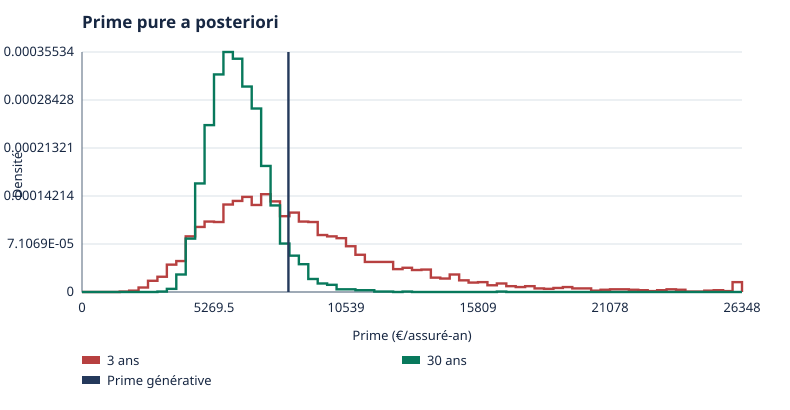

In [10]:
var randomFrequency = new Random(20260825);
var premiumSamples = new Dictionary<string, double[]>();
foreach (var h in histories)
{
    var frequency = frequencyPost[h.Name];
    var severity = severityPost[h.Name];
    // Indexer les deux vecteurs au même rang transporte leur dépendance postérieure.
    var draws = severity.Mu.Zip(severity.Sigma, (mu, sigma) =>
        Gamma.Sample(randomFrequency, frequency.Shape, frequency.Rate) * Math.Exp(mu + sigma * sigma / 2)).ToArray();
    RequireActu(draws.Length == 4_000 && draws.All(x => x > 0 && double.IsFinite(x)), "Tirages de prime invalides.");
    premiumSamples[h.Name] = draws;
    double q05 = QuantileActu(draws, .05), q50 = QuantileActu(draws, .5), q95 = QuantileActu(draws, .95);
    RequireActu(q05 <= q50 && q50 <= q95, "Ordre des quantiles incohérent.");
    Console.WriteLine($"{h.Name}: moyenne {draws.Average():F0} € | Q5 {q05:F0} € | Q50 {q50:F0} € | Q95 {q95:F0} € | CV {StdActu(draws)/draws.Average():P1}");
}
double posteriorLimit = premiumSamples.Values.Select(x => QuantileActu(x, .995)).Max();
ActuSeries youngDensity = HistogramActu(premiumSamples["B_jeune"], posteriorLimit, 70, "3 ans", "#b74040", true);
ActuSeries matureDensity = HistogramActu(premiumSamples["B_mature"], posteriorLimit, 70, "30 ans", "#08795c", true);
PlotActu("Prime pure a posteriori", "Prime (€/assuré-an)", "Densité", youngDensity, matureDensity,
    new ActuSeries("Prime générative", "#24395b", [bPortfolio.NetPremium, bPortfolio.NetPremium], [0, Math.Max(youngDensity.Y.Max(), matureDensity.Y.Max())]));

### Lecture des primes possibles

La courbe du portefeuille mûr est généralement plus concentrée, car davantage d’observations éclairent ses deux paramètres de sévérité et sa fréquence. La référence générative vérifie l’ordre de grandeur dans ce monde où la vérité est connue.

## 4. Prime commerciale et chargement d’incertitude

On compare une convention multiplicative, $P=\pi/(1-c)$, à la convention additive, $P=\pi(1+c)$. Pour le chargement de sécurité, on vise explicitement un quantile de la prime inconnue.

In [11]:
const double expenses = .05, contingencies = .03, margin = .02;
double standardLoading = expenses + contingencies + margin;

foreach (var p in portfolio)
{
    // Une fraction de la prime totale et une fraction de la prime pure ont des assiettes différentes.
    double multiplicative = p.NetPremium / (1 - standardLoading);
    double additive = p.NetPremium * (1 + standardLoading);
    RequireActu(multiplicative > additive, "L’ordre des conventions de chargement est incorrect.");
    Console.WriteLine($"{p.Name}: pure {p.NetPremium:F1} € | multiplicative {multiplicative:F1} € | additive {additive:F1} € | écart {multiplicative-additive:F1} €");
}
Console.WriteLine("Chargements de sécurité additifs pour les deux historiques.");
foreach (var h in histories)
{
    var samples = premiumSamples[h.Name];
    double basePremium = samples.Average();
    foreach (double q in new[] { .50, .75, .95, .99 })
    {
        double price = QuantileActu(samples, q);
        double security = price / basePremium - 1;
        Console.WriteLine($"{h.Name} | Q{100*q:F0} | {security:P1} | prime associée {price:F0} €");
    }
}

A_auto: pure 1439.3 € | multiplicative 1599.3 € | additive 1583.3 € | écart 16.0 €


B_rc_med: pure 8240.6 € | multiplicative 9156.3 € | additive 9064.7 € | écart 91.6 €


Chargements de sécurité additifs pour les deux historiques.


B_jeune | Q50 | -10.5 % | prime associée 7879 €


B_jeune | Q75 | 18.2 % | prime associée 10403 €


B_jeune | Q95 | 83.9 % | prime associée 16187 €


B_jeune | Q99 | 168.0 % | prime associée 23592 €


B_mature | Q50 | -1.8 % | prime associée 6164 €


B_mature | Q75 | 10.7 % | prime associée 6955 €


B_mature | Q95 | 33.9 % | prime associée 8412 €


B_mature | Q99 | 55.8 % | prime associée 9786 €


### Lecture du chargement

L’écart entre conventions grandit avec la prime pure. Pour une exposition courte, le quantile de sécurité peut se situer loin de sa moyenne. L’écart résulte de la distribution de l’estimation autant que du niveau moyen du risque.

### Exercice 2 — Chargement du portefeuille jeune au quantile 80

Calculez le chargement de sécurité additif du portefeuille jeune au quantile 80. Comparez-le au chargement commercial standard de 10 % et précisez la différence de convention.

In [12]:
static double? EstimerChargementSécurité(double[] primes, double quantile)
{
    // TODO étudiant : utiliser le quantile et la moyenne de la même distribution.
    return null;
}
var primeJeune = premiumSamples["B_jeune"];
double? chargementQ80 = EstimerChargementSécurité(primeJeune, .80);
if (chargementQ80 is double valeur)
{
    RequireActu(Math.Abs(primeJeune.Average() * (1 + valeur) - QuantileActu(primeJeune, .80)) < 1e-8,
        "La prime chargée doit atteindre le quantile cible.");
    Console.WriteLine($"Chargement de sécurité Q80 : {valeur:P1} | standard commercial : 10 %.");
}
else
    Console.WriteLine("À compléter : mesure du chargement au Q80.");

À compléter : mesure du chargement au Q80.


## 5. Décision tarifaire et antisélection

Une grille de chargements traduit les décisions possibles en probabilité de perte technique et marge attendue par assuré. Puis les bons risques peuvent quitter le portefeuille dès que le tarif dépasse leur disposition à payer.

Profil       Prime pure        CV   Q95 sécurité   Prime 10 %


A_auto             1439    connue              —         1599


B_mature           6280    19.0 %         33.9 %         6978


B_jeune            8803    49.9 %         83.9 %         9781


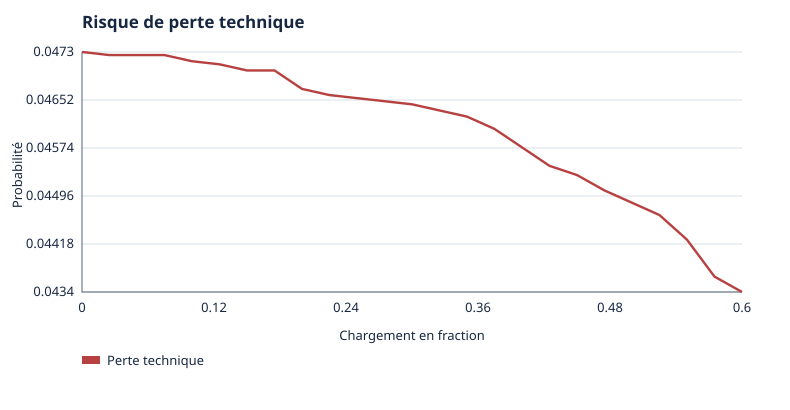

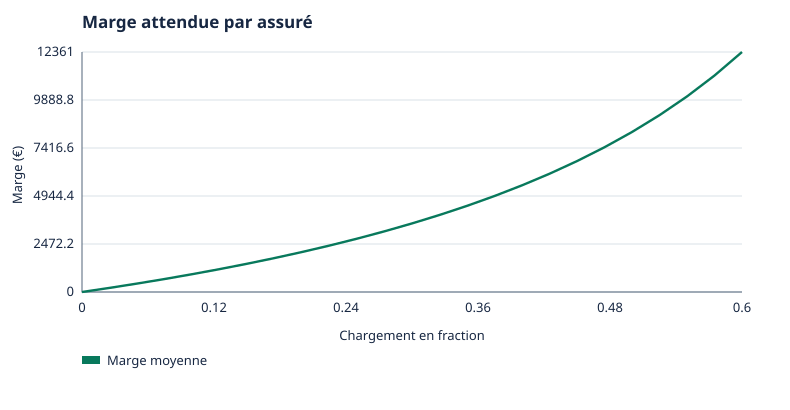

À 10 % : P(perte)=4.71 %, marge=916 €. À 60 % : P(perte)=4.34 %, marge=12361 €.


In [13]:
Console.WriteLine($"{"Profil",-12} {"Prime pure",10} {"CV",9} {"Q95 sécurité",14} {"Prime 10 %",12}");
Console.WriteLine($"{"A_auto",-12} {portfolio[0].NetPremium,10:F0} {"connue",9} {"—",14} {portfolio[0].NetPremium/(1-standardLoading),12:F0}");
foreach (var h in histories.Reverse())
{
    double[] samples = premiumSamples[h.Name];
    double avg = samples.Average();
    Console.WriteLine($"{h.Name,-12} {avg,10:F0} {StdActu(samples)/avg,9:P1} {QuantileActu(samples,.95)/avg-1,14:P1} {avg/(1-standardLoading),12:F0}");
}

// Les deux courbes ont des unités distinctes pour éviter un axe ambigu.
var loadGrid = Enumerable.Range(0, 25).Select(i => .6 * i / 24).ToArray();
var bLosses = annualLoss[bPortfolio.Name];
double[] lossRates = loadGrid.Select(c => bLosses.Count(y => y > bPortfolio.NetPremium / (1 - c)) / (double)bLosses.Length).ToArray();
double[] margins = loadGrid.Select(c => bPortfolio.NetPremium / (1 - c) - bPortfolio.NetPremium).ToArray();
RequireActu(lossRates.Zip(lossRates.Skip(1)).All(p => p.First >= p.Second)
    && margins.Zip(margins.Skip(1)).All(p => p.First <= p.Second), "Sensibilité au chargement incohérente.");
PlotActu("Risque de perte technique", "Chargement en fraction", "Probabilité", new ActuSeries("Perte technique", "#b74040", loadGrid, lossRates));
PlotActu("Marge attendue par assuré", "Chargement en fraction", "Marge (€)", new ActuSeries("Marge moyenne", "#08795c", loadGrid, margins));
Console.WriteLine($"À 10 % : P(perte)={lossRates[4]:P2}, marge={margins[4]:F0} €. À 60 % : P(perte)={lossRates[^1]:P2}, marge={margins[^1]:F0} €.");

### Lecture du risque technique

Augmenter la prime réduit la fréquence avec laquelle le coût annuel la dépasse, tout en augmentant la marge théorique. Les deux courbes supposent le portefeuille inchangé. La simulation suivante retire cette hypothèse pour les bons risques.

In [14]:
const double goodRisk = .03, badRisk = .09;
double goodShare = .50, willingness = goodRisk * bPortfolio.MeanSeverity * 1.25;
Console.WriteLine($"Disposition à payer d’un bon risque : {willingness:F0} €.");
Console.WriteLine("Tour | part de bons risques | prime pure | prime commerciale | les bons restent");
double previousPrice = 0;
for (int round = 0; round < 6; round++)
{
    // La hausse provient du changement de mélange, à coûts conditionnels inchangés.
    double mix = goodShare * goodRisk + (1 - goodShare) * badRisk;
    double pure = mix * bPortfolio.MeanSeverity;
    double commercial = pure / (1 - standardLoading);
    RequireActu(commercial >= previousPrice, "La sortie de bons risques ne doit pas réduire le tarif du mélange.");
    previousPrice = commercial;
    bool retain = commercial <= willingness;
    Console.WriteLine($"{round+1,4} | {goodShare,20:P1} | {pure,10:F0} | {commercial,17:F0} | {(retain ? "oui" : "non")}");
    if (retain) break;
    goodShare *= 0.55;
}

Disposition à payer d’un bon risque : 6180 €.


Tour | part de bons risques | prime pure | prime commerciale | les bons restent


   1 |               50.0 % |       9889 |             10988 | non


   2 |               27.5 % |      12114 |             13460 | non


   3 |               15.1 % |      13337 |             14819 | non


   4 |                8.3 % |      14011 |             15567 | non


   5 |                4.6 % |      14381 |             15979 | non


   6 |                2.5 % |      14584 |             16205 | non


### Lecture de la spirale

Les sorties modifient la composition du portefeuille et augmentent la prime pure au tour suivant. Cette simulation rend visible la rétroaction entre le prix et la population assurée, distincte du choix d’un quantile de sécurité.

### Exercice 3 — Choix tarifaire sur trois profils

Pour A_auto, B_rc_mature et B_rc_jeune, reprenez le tableau de décision. Comparez les CV et chargements au Q95. Justifiez les conditions qui vous feraient choisir le tarif standard, une surprime provisoire ou une collecte d’information plus longue.

In [15]:
#nullable enable
static string? JustifierTarif(string profil, double prime, double? cv, double? chargementDeSécurité)
{
    // TODO étudiant : relier le choix tarifaire à l'incertitude et à la concurrence.
    return null;
}
var critèresTarifaires = new List<(string Profil, double Prime, double? Cv, double? Q95)> {
    ("A_auto", portfolio[0].NetPremium, null, null)
};
foreach (var h in histories)
{
    double[] valeurs = premiumSamples[h.Name];
    double moyenne = valeurs.Average();
    critèresTarifaires.Add((h.Name, moyenne, StdActu(valeurs) / moyenne, QuantileActu(valeurs, .95) / moyenne - 1));
}
foreach (var p in critèresTarifaires)
    Console.WriteLine(JustifierTarif(p.Profil, p.Prime, p.Cv, p.Q95) ?? $"À compléter : stratégie motivée pour {p.Profil}.");

À compléter : stratégie motivée pour A_auto.


À compléter : stratégie motivée pour B_jeune.


À compléter : stratégie motivée pour B_mature.


## À retenir

- La prime pure d’une perte composée est le produit de la fréquence et du coût moyen conditionnel. Elle peut coexister avec de fortes différences de quantiles.
- La connaissance des paramètres change la nature du tarif. La simulation de pertes représente un risque aléatoire, tandis que la distribution de prime représente une incertitude d’estimation.
- Le chargement modifie à la fois la marge et, dans un marché sélectif, le mélange d’assurés.

## Vérifiez votre compréhension

**Pourquoi un chargement de sécurité élevé peut-il augmenter le risque futur du portefeuille ?**

<details><summary>Réponse</summary>

Si le prix dépasse ce que les bons risques acceptent de payer, leurs départs augmentent la fréquence moyenne des personnes qui restent.

</details>

**Pourquoi propager $\mu$ et $\sigma$ à partir du même tirage ?**

<details><summary>Réponse</summary>

L’espérance lognormale dépend des deux paramètres. Mélanger arbitrairement leurs rangs détruit leur dépendance a posteriori.

</details>

## Pour aller plus loin

- [Effet du partial pooling sur vingt segments](Actuariat-02-Freq-Sev-Hierarchique-CSharp.ipynb).
- [Inférence par échantillonnage dans PyMC](https://www.pymc.io/projects/docs/en/stable/api/generated/pymc.sample.html).
- [Algorithmes d’inférence d’Infer.NET](https://dotnet.github.io/infer/userguide/Working%20with%20different%20inference%20algorithms.html).